# CSL236 – Mid-Term Project: Preparing Network-Traffic Data for Intrusion Detection

| | |
|---|---|
| **Team No.** | `____` *(fill in your team number before submitting)* |
| **Member 1** | Rudra Kumar Sharma — Roll No. 24CSU175 |
| **Member 2** | Bhavishyata Yadav — Roll No. 24CSU036 |
| **Member 3** | Bhavya Jain — Roll No. 24CSU037 |
| **Course** | CSL236 – Introduction to AI & ML · B.Tech CSE, Semester 5 · The NorthCap University |
| **Dataset** | NSL-KDD (KDDTrain+ and KDDTest+ combined) |

## Problem statement
A network intrusion-detection system (IDS) looks at each network connection and must decide whether it is **normal** or an **attack**. Each connection is described by 41 numbers/labels (duration, bytes sent, protocol, how many errors it caused, ...). This is a **binary classification** problem: `0 = normal`, `1 = attack`.

This notebook is about the step *before* modelling: taking the raw table and making it fit for a machine-learning algorithm. The grading focus is the **process**, so every stage below says **what** we did and **why**. The model at the end is deliberately a simple baseline.

This is the first half of our larger project **ZeroWatch** (AI-based zero-day attack detection). ZeroWatch uses the same dataset and the same preprocessing ideas, but trains an Autoencoder to detect attack types it has never seen.

## Roadmap
A. Understand the data → **split into train/test** → B. Missing values → C. Encode categories → D. Binning → E. Scaling / log transform → F. Outliers → G. Dimensionality reduction → H. Train a model.

> **Rule we follow everywhere:** the train/test split happens *before* anything is fitted. Every imputer, encoder, scaler and selector learns only from the training rows and is then applied unchanged to the test rows. Fitting on the full data first would leak information from the test set into training (data leakage).

In [1]:
import io, warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, KBinsDiscretizer,
                                   FunctionTransformer, StandardScaler)
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60, "display.width", 140)
sns.set_theme(style="whitegrid")
SEED = 42

## Stage A – Understanding the data

**Dataset.** NSL-KDD is the cleaned version of the classic KDD'99 intrusion-detection data. Every row is one network connection described by 41 features, labelled either `normal` or with the name of an attack (`neptune`, `smurf`, `nmap`, ...). The 41 features fall into groups: basic connection info (duration, protocol, bytes), content features (failed logins, root shell), and traffic statistics over a time window (error rates, connection counts).

**Why it matters.** Signature-based IDS tools only catch attacks they already know. A model that learns what traffic looks like is the first step towards catching new ones. That is the goal of our larger ZeroWatch project.

We load the official train and test files and concatenate them, because we create our own train/test split later (so that we control exactly when each preprocessing step is fitted).

In [2]:
COL_NAMES = [
    "duration","protocol_type","service","flag","src_bytes","dst_bytes","land","wrong_fragment","urgent",
    "hot","num_failed_logins","logged_in","num_compromised","root_shell","su_attempted","num_root",
    "num_file_creations","num_shells","num_access_files","num_outbound_cmds","is_host_login",
    "is_guest_login","count","srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
    "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count","dst_host_srv_count",
    "dst_host_same_srv_rate","dst_host_diff_srv_rate","dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate","dst_host_serror_rate","dst_host_srv_serror_rate","dst_host_rerror_rate",
    "dst_host_srv_rerror_rate","label","difficulty"]
BASE = "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/"

def fetch(name):
    r = requests.get(BASE + name, timeout=60); r.raise_for_status()
    return pd.read_csv(io.StringIO(r.text), names=COL_NAMES)

raw = pd.concat([fetch("KDDTrain%2B.txt"), fetch("KDDTest%2B.txt")], ignore_index=True)
raw = raw.drop(columns=["difficulty"])      # a score the dataset authors added; not a traffic feature
raw["label"] = raw["label"].str.strip()
print("Shape as loaded:", raw.shape)

Shape as loaded: (148517, 42)


In [3]:
# Exact duplicate rows: KDDTrain+ and KDDTest+ overlap a little.
n_dup = raw.duplicated().sum()
print(f"Exact duplicate rows: {n_dup}")
df = raw.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape)

Exact duplicate rows: 610


Shape after dropping duplicates: (147907, 42)


**Decision – drop exact duplicates.** If an identical row ended up in both the training and the test set, the model would be "tested" on something it has already memorised, which inflates the score and hides real performance. We remove them *before* splitting. (Removing duplicates is a row-level clean-up that learns nothing from the data, so it cannot leak.)

In [4]:
print("Data types of every column:")
dt = df.dtypes.astype(str)
half = (len(dt) + 1) // 2
left, right = dt.iloc[:half].reset_index(), dt.iloc[half:].reset_index()
left.columns = ["column", "dtype"]; right.columns = ["column ", "dtype "]
display(pd.concat([left, right.reset_index(drop=True)], axis=1).fillna(""))
print(dt.value_counts().to_dict())
print("\nSummary statistics (numeric columns):")
display(df.describe().T.round(3))

Data types of every column:


,column,dtype,column,dtype
0,duration,int64,is_guest_login,int64
1,protocol_type,object,count,int64
2,service,object,srv_count,int64
3,flag,object,serror_rate,float64
4,src_bytes,int64,srv_serror_rate,float64
5,dst_bytes,int64,rerror_rate,float64
6,land,int64,srv_rerror_rate,float64
7,wrong_fragment,int64,same_srv_rate,float64
8,urgent,int64,diff_srv_rate,float64
9,hot,int64,srv_diff_host_rate,float64


{'int64': 23, 'float64': 15, 'object': 4}

Summary statistics (numeric columns):


,count,mean,std,min,25%,50%,75%,max
duration,147907.0,277.921,2465.688,0.0,0.00,0.00,0.00,5.771500e+04
src_bytes,147907.0,40386.798,5420754.804,0.0,0.00,44.00,278.00,1.379964e+09
dst_bytes,147907.0,17158.351,3711153.877,0.0,0.00,0.00,580.00,1.309937e+09
land,147907.0,0.000,0.014,0.0,0.00,0.00,0.00,1.000000e+00
wrong_fragment,147907.0,0.020,0.240,0.0,0.00,0.00,0.00,3.000000e+00
urgent,147907.0,0.000,0.019,0.0,0.00,0.00,0.00,3.000000e+00
hot,147907.0,0.190,2.017,0.0,0.00,0.00,0.00,1.010000e+02
num_failed_logins,147907.0,0.004,0.072,0.0,0.00,0.00,0.00,5.000000e+00
logged_in,147907.0,0.404,0.491,0.0,0.00,0.00,1.00,1.000000e+00
num_compromised,147907.0,0.256,22.277,0.0,0.00,0.00,0.00,7.479000e+03


In [5]:
miss = pd.DataFrame({"missing_count": df.isna().sum(), "missing_pct": (df.isna().mean()*100).round(3)})
print("Missing values per column (only columns with >0 shown):")
display(miss[miss.missing_count > 0] if (miss.missing_count > 0).any() else "→ no column has any missing value")
print("Total missing cells:", int(df.isna().sum().sum()))

Missing values per column (only columns with >0 shown):


'→ no column has any missing value'

Total missing cells: 0


In [6]:
# Separate numerical from categorical columns, and create the target.
target_col = "label"
feature_df = df.drop(columns=[target_col])
categorical_cols = feature_df.select_dtypes(include="object").columns.tolist()
numerical_cols   = feature_df.select_dtypes(exclude="object").columns.tolist()
print(f"Categorical ({len(categorical_cols)}): {categorical_cols}")
print(f"Numerical   ({len(numerical_cols)}): {numerical_cols}")

# Of the numerical columns, which are really 0/1 flags?
binary_cols = [c for c in numerical_cols if set(df[c].unique()) == {0, 1}]
print(f"\nBinary 0/1 flags ({len(binary_cols)}): {binary_cols}")
print("su_attempted values:", sorted(df['su_attempted'].unique()), "(0/1/2 → a small count, kept numeric)")
print("num_outbound_cmds distinct values:", df['num_outbound_cmds'].unique(), "(a constant column → no information; dropped in Stage E)")

Categorical (3): ['protocol_type', 'service', 'flag']
Numerical   (38): ['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']

Binary 0/1 flags (5): ['land', 'logged_in', 'root_shell', 'is_host_login', 'is_guest_login']
su_attempted values: [np.int64(0), np.int64(1), np.int64(2)] (0/1/2 → a small count, kept numeric)
num_outbound_cmds distinct values: [0] (a 

**What we found.**
- The table has **no missing values** (checked properly in Stage B).
- **3 categorical (text) columns:** `protocol_type`, `service`, `flag`. They have no natural order, so they are *nominal*.
- **38 numerical columns.** Five of them are 0/1 flags (`land`, `logged_in`, `root_shell`, `is_host_login`, `is_guest_login`); `num_outbound_cmds` is the constant 0 in every row, so it carries no information and is dropped in Stage E; the rest are durations, byte counts, counts and rates.
- `su_attempted` is mostly 0/1 but contains a few `2`s (a known quirk of the dataset), so we treat it as a plain number and not as a flag.

**Target.** The label is 1 of ~40 attack names or `normal`. We turn it into a **binary target** (a 0/1 mapping): `normal → 0`, anything else `→ 1`. Predicting the exact attack name is not needed for this mid-term, and many attack names have only a handful of rows.

label
normal (0)    76967
attack (1)    70940
Name: count, dtype: int64


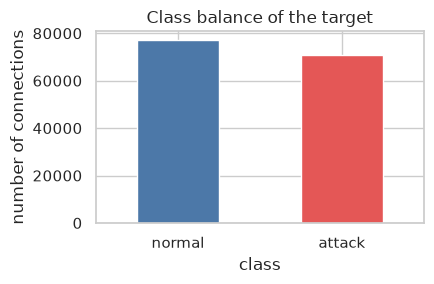

In [7]:
y_all = (df[target_col] != "normal").astype(int)         # binary 0/1 mapping of the target
X_all = df.drop(columns=[target_col])

print(y_all.value_counts().rename({0: "normal (0)", 1: "attack (1)"}))
fig, ax = plt.subplots(figsize=(4.5, 3))
y_all.map({0: "normal", 1: "attack"}).value_counts().plot.bar(ax=ax, color=["#4C78A8", "#E45756"])
ax.set_title("Class balance of the target"); ax.set_xlabel("class"); ax.set_ylabel("number of connections")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Class balance.** The classes are close to 50/50, so we do **not** need resampling (SMOTE / undersampling). Accuracy is also a meaningful metric here, and we will report precision, recall and F1 next to it anyway.

### Train / test split — done now, before anything is fitted
We hold out 20 % of the rows as a test set, **stratified** on the target so both parts keep the same normal/attack ratio. From this point on, every "fit" uses `X_train` only.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)
print("train:", X_train.shape, " test:", X_test.shape)
print("attack share  train: %.3f   test: %.3f" % (y_train.mean(), y_test.mean()))

train: (118325, 41)  test: (29582, 41)
attack share  train: 0.480   test: 0.480


## Stage B – Handling missing values

**Finding.** The count above shows **0 missing values in every column**. Before accepting that, we also look for *hidden* missing values: placeholder strings such as `?`, `-` or an empty string in the text columns, and infinite values in the numeric ones.

In [9]:
placeholders = {"?", "-", "", "NA", "N/A", "null", "None"}
for c in categorical_cols:
    bad = set(X_train[c].astype(str).str.strip().unique()) & placeholders
    print(f"{c:14s} distinct values: {X_train[c].nunique():3d}   placeholder-like values: {bad or 'none'}")
print("\ninfinite values in numeric columns:", int(np.isinf(X_train[numerical_cols]).sum().sum()))
print("negative values in numeric columns :", int((X_train[numerical_cols] < 0).sum().sum()))

protocol_type  distinct values:   3   placeholder-like values: none
service        distinct values:  69   placeholder-like values: none
flag           distinct values:  11   placeholder-like values: none

infinite values in numeric columns: 0
negative values in numeric columns : 0


**Decision per column.** No column has missing, placeholder or infinite values, so **no column needs to be imputed and none is dropped for missingness**. We skip dropping and imputing on this data, and say so explicitly rather than silently.

**Safety net kept in the pipeline.** A deployed IDS receives live records that can arrive with a field blank, and the saved preprocessor must not crash on that. So the pipeline we build contains an imputer for each column type, **fitted on the training rows only**:

| column type | strategy | reason |
|---|---|---|
| numerical | **median** | the byte/count columns are extremely skewed (see Stage E); the mean would be dragged up by a few huge connections, the median is not |
| categorical (nominal) | **most frequent (mode)** | there is no meaningful average of a text category |
| binary flags | **most frequent (mode)** | keeps the value in {0, 1} |

On this dataset these imputers change nothing (no gaps), which is expected.

## Stage C – Converting categorical values to numbers

ML models need numbers, but the right numbers depend on the type of column. We separate three kinds:

| kind | columns | scheme | why |
|---|---|---|---|
| **Binary** | `land`, `logged_in`, `root_shell`, `is_host_login`, `is_guest_login`, and the target | **0/1 mapping** (already 0/1; target mapped above) | two states only, nothing to invent |
| **Nominal** (no order) | `protocol_type` (3 values), `service` (69), `flag` (11) | **one-hot encoding** | giving `tcp/udp/icmp` the codes 0/1/2 would tell the model that icmp is "bigger" than tcp. One-hot makes one 0/1 column per category so no order is implied |
| **Ordinal** (ordered) | `duration_band` (created in Stage D) | **ordinal encoding with an explicit order** | its categories really are ordered: instant < short < medium < long |

For one-hot we use `handle_unknown="ignore"`: if a category appears in the test set (or in live traffic) that was never seen in training, it becomes an all-zero row instead of an error.

*Why not label encoding for `service`?* It would mean the model could treat `ftp` (code 20) as "twice as much" as `domain` (code 10). That is meaningless for a nominal feature, so we avoid it.

In [10]:
# Collect the preprocessing steps here; each stage below adds its piece and previews it.
steps = []

def preview(transformer, cols, n=4, title=""):
    '''Fit `transformer` on the TRAINING rows of `cols` only, show a few transformed rows.'''
    t = clone(transformer).fit(X_train[cols])
    out = t.transform(X_train[cols].head(n))
    out = pd.DataFrame(out, columns=t.get_feature_names_out() if hasattr(t, "get_feature_names_out") else None)
    print(title); display(out.round(3))

nominal_cols = ["protocol_type", "service", "flag"]
nominal_tf = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),                     # Stage B safety net
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
steps.append(("nominal_onehot", nominal_tf, nominal_cols))
binary_tf = SimpleImputer(strategy="most_frequent")                           # keeps 0/1 as they are
steps.append(("binary_passthrough", binary_tf, binary_cols))

print("Categories learned from the training rows:")
for c in nominal_cols:
    print(f"  {c:14s} {X_train[c].nunique():3d} categories -> {X_train[c].nunique()} one-hot columns")
preview(nominal_tf, ["protocol_type"], title="\nOne-hot example (protocol_type):")

Categories learned from the training rows:
  protocol_type    3 categories -> 3 one-hot columns
  service         69 categories -> 69 one-hot columns
  flag            11 categories -> 11 one-hot columns

One-hot example (protocol_type):


,protocol_type_icmp,protocol_type_tcp,protocol_type_udp
0,0.0,1.0,0.0
1,0.0,1.0,0.0
2,0.0,0.0,1.0
3,0.0,1.0,0.0


## Stage D – Binning (discretisation)

Binning turns a continuous column into ranges. It helps when *which range* matters more than the exact number, or when a column is dominated by a few distinct values. We apply it to two columns and justify the boundaries:

**1. `duration` – domain-defined bins.** Look at the distribution first:

In [11]:
print((X_train["duration"] == 0).mean().round(3), "of connections last 0 seconds")
print(X_train["duration"].describe(percentiles=[.5, .9, .95, .99]).round(1))

0.909 of connections last 0 seconds
count    118325.0
mean        279.0
std        2476.9
min           0.0
50%           0.0
90%           0.0
95%          10.0
99%        8183.3
max       57715.0
Name: duration, dtype: float64


Most connections last 0 s, so equal-width or equal-frequency bins would collapse (several quantile edges would all be 0). We therefore use **domain-defined** boundaries that match how network sessions behave:

| band | seconds | meaning |
|---|---|---|
| `instant` | 0 | a single request/response (ping, DNS, a failed or scanned connection) |
| `short` | 1 – 60 | ordinary web / service request |
| `medium` | 61 – 600 | interactive session |
| `long` | > 600 | long-lived session (file transfer, remote login) |

The four bands have a natural order, so they are **ordinal-encoded with the order written out explicitly**: `instant = 0, short = 1, medium = 2, long = 3`. The boundaries are fixed by us and not learned from the data, so applying them cannot leak anything from the test set.

In [12]:
DURATION_ORDER = ["instant", "short", "medium", "long"]          # explicit ordinal order

def to_duration_band(X):
    d = pd.DataFrame(X).iloc[:, 0]
    band = pd.cut(d, bins=[-np.inf, 0, 60, 600, np.inf], labels=DURATION_ORDER)
    return pd.DataFrame({"duration_band": band.astype(str)}, index=d.index)

duration_tf = Pipeline([
    ("band", FunctionTransformer(to_duration_band, feature_names_out=lambda t, n: ["duration_band"])),
    ("ordinal", OrdinalEncoder(categories=[DURATION_ORDER])),     # instant=0 < short=1 < medium=2 < long=3
])
steps.append(("duration_band", duration_tf, ["duration"]))

bands = to_duration_band(X_train[["duration"]])["duration_band"]
display(bands.value_counts().reindex(DURATION_ORDER).to_frame("rows in training set"))

,rows in training set
duration_band,
instant,107524
short,6564
medium,1072
long,3165


**2. `count` – equal-frequency (quantile) bins.** `count` is the number of connections to the same host in the last 2 seconds (0–511). A flood of connections is the signature of DoS attacks, and what matters is *how busy* the host is, in rough levels, not whether it was 213 or 214. We cut it into **4 equal-frequency bins**, so each level holds roughly a quarter of the training rows. Equal-frequency was chosen over equal-width because `count` is heavily skewed: equal-width bins would put almost every row in the first bin. We use 4 and not 5 bins because 22.6 % of all connections have `count == 1`; with 5 bins the 20 % quantile edge lands on that tie and the first bin ends up empty. The bin edges are learned from the training rows only.

In [13]:
count_tf = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("bins", KBinsDiscretizer(n_bins=4, encode="ordinal", strategy="quantile", subsample=None)),
])
steps.append(("count_bins", count_tf, ["count"]))

kb = clone(count_tf).fit(X_train[["count"]])
edges = kb.named_steps["bins"].bin_edges_[0]
print("Bin edges learned on training rows:", np.round(edges, 1))
print(pd.Series(kb.transform(X_train[["count"]]).ravel()).value_counts(normalize=True).sort_index().round(3).to_string())

Bin edges learned on training rows: [  0.   2.  13. 141. 511.]


0.0    0.226
1.0    0.269
2.0    0.255
3.0    0.250


## Stage E – Scaling and transformation

**Why scale?** The features live on wildly different scales: `src_bytes` goes up to hundreds of millions while rates are between 0 and 1. Distance- and gradient-based models (logistic regression here, and the neural-network Autoencoder in ZeroWatch) are dominated by the large-valued columns unless everything is brought to a comparable scale. We use **standardisation** (subtract the mean, divide by the standard deviation), fitted on the training rows only.

**Why a log transform first?** Standardising a heavily skewed column does not fix the skew; a few giant values still stretch the range. For right-skewed, non-negative columns we apply `log1p(x) = log(1 + x)` first, which compresses the long tail and keeps zeros at zero. We decide *which* columns by measuring skewness on the training rows: skew > 1 and non-negative and not already a 0–1 rate.

In [14]:
already_handled = set(nominal_cols) | set(binary_cols) | {"duration", "count"}
continuous_cols = [c for c in numerical_cols if c not in already_handled]
skew = X_train[continuous_cols].skew()

constant_cols = [c for c in continuous_cols if X_train[c].nunique() <= 1]
log_cols = [c for c in continuous_cols
            if c not in constant_cols and X_train[c].min() >= 0 and X_train[c].max() > 1 and skew[c] > 1]
scale_only_cols = [c for c in continuous_cols if c not in log_cols and c not in constant_cols]

print(f"{len(log_cols)} skewed columns get log1p → standardise:\n  {log_cols}")
print(f"\n{len(scale_only_cols)} columns are only standardised (rates, mild skew):\n  {scale_only_cols}")
print(f"\nconstant column(s) (no information): {constant_cols}")

13 skewed columns get log1p → standardise:
  ['src_bytes', 'dst_bytes', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'num_compromised', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'srv_count']

17 columns are only standardised (rates, mild skew):
  ['serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']

constant column(s) (no information): ['num_outbound_cmds']


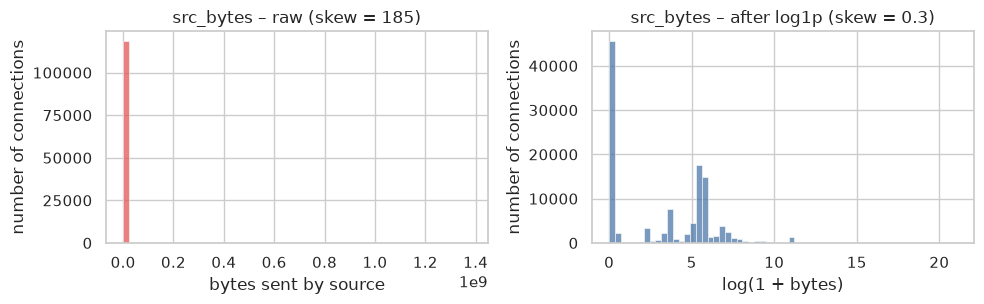

,skew before,skew after log1p,share of zeros
src_bytes,185.096,0.337,0.385
dst_bytes,281.130,0.448,0.520
wrong_fragment,12.100,11.755,0.992
urgent,107.010,95.092,1.000
hot,14.588,9.049,0.975
num_failed_logins,21.146,16.729,0.996
num_compromised,246.980,26.447,0.989
su_attempted,44.465,43.267,0.999
num_root,235.370,27.137,0.995
num_file_creations,88.476,32.884,0.998


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
sns.histplot(X_train["src_bytes"], bins=60, ax=axes[0], color="#E45756")
axes[0].set_title("src_bytes – raw (skew = %.0f)" % X_train["src_bytes"].skew())
axes[0].set_xlabel("bytes sent by source"); axes[0].set_ylabel("number of connections")
logged = np.log1p(X_train["src_bytes"])
sns.histplot(logged, bins=60, ax=axes[1], color="#4C78A8")
axes[1].set_title("src_bytes – after log1p (skew = %.1f)" % logged.skew())
axes[1].set_xlabel("log(1 + bytes)"); axes[1].set_ylabel("number of connections")
plt.tight_layout(); plt.show()

comp = pd.DataFrame({"skew before": X_train[log_cols].skew(),
                     "skew after log1p": np.log1p(X_train[log_cols]).skew(),
                     "share of zeros": (X_train[log_cols] == 0).mean()}).round(3)
display(comp)

**Reading the table.** `log1p` works very well for the genuinely continuous columns: `src_bytes` goes from skew 185 to 0.34, `dst_bytes` from 281 to 0.45, `srv_count` from 4.7 to 0.9. It does **not** fix the sparse count columns (`urgent`, `num_shells`, `su_attempted`, `wrong_fragment`, ...). Those are over 99 % zeros, so no monotone transform can make them symmetric. We still apply `log1p` to them (it does no harm and tames the rare large values, e.g. `num_compromised` drops from 247 to 26), but we accept that they stay skewed. That is the nature of the data: a non-zero `num_shells` is a rare and meaningful event, and standardising keeps it as a clearly visible signal.

In [16]:
log_tf = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
])
scale_tf = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
steps.append(("log_scaled", log_tf, log_cols))
steps.append(("scaled", scale_tf, scale_only_cols))
# `constant_cols` is simply not added to any step → it is dropped by the ColumnTransformer

## Stage F – Outlier treatment

We detect outliers with the **IQR rule**: a value is an outlier if it lies below `Q1 − 1.5·IQR` or above `Q3 + 1.5·IQR`. The fences come from the **training rows** only. Then the key question for each column is: *is the outlier a genuine value or an error?*

Outliers are not deleted by reflex. We first check **who** the outliers are, specifically whether they cluster in attack traffic.

In [17]:
def iqr_fences(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for c in log_cols + scale_only_cols:
    s = X_train[c]; lo, hi = iqr_fences(s)
    out = (s < lo) | (s > hi)            # if IQR = 0 every non-zero value is flagged (zero-inflated column)
    rows.append({"column": c, "IQR=0?": "yes" if hi == lo else "", "outliers": int(out.sum()),
                 "outlier_%": 100 * out.mean(),
                 "% of outliers that are attacks": 100 * y_train[out].mean() if out.any() else np.nan})
out_tbl = pd.DataFrame(rows).sort_values("outlier_%", ascending=False).round(1)
base = 100 * y_train.mean()
print(f"Attack share over ALL training rows (base rate): {base:.1f} %")
display(out_tbl[out_tbl["outliers"] > 0].reset_index(drop=True))
print(f"{(out_tbl['outliers'] == 0).sum()} further columns have no IQR outliers at all.")

# Error or genuine? First test for impossible values (an error would look like this).
rate_cols = [c for c in continuous_cols if c.endswith("_rate")]
print("\nAll *_rate columns inside [0, 1]:", bool(((X_train[rate_cols] >= 0) & (X_train[rate_cols] <= 1)).all().all()))
print("Any negative count/byte value   :", bool((X_train[continuous_cols] < 0).any().any()))

Attack share over ALL training rows (base rate): 48.0 %


,column,IQR=0?,outliers,outlier_%,% of outliers that are attacks
0,srv_diff_host_rate,yes,26690,22.6,16.0
1,dst_host_rerror_rate,yes,25467,21.5,74.7
2,dst_host_same_src_port_rate,,23767,20.1,48.3
3,dst_host_srv_diff_host_rate,,22066,18.6,23.1
4,dst_host_srv_rerror_rate,yes,21180,17.9,75.2
5,dst_bytes,,20835,17.6,6.7
6,rerror_rate,yes,17455,14.8,84.9
7,srv_rerror_rate,yes,17379,14.7,83.0
8,src_bytes,,13055,11.0,32.8
9,srv_count,,11848,10.0,34.3


8 further columns have no IQR outliers at all.

All *_rate columns inside [0, 1]: True
Any negative count/byte value   : False


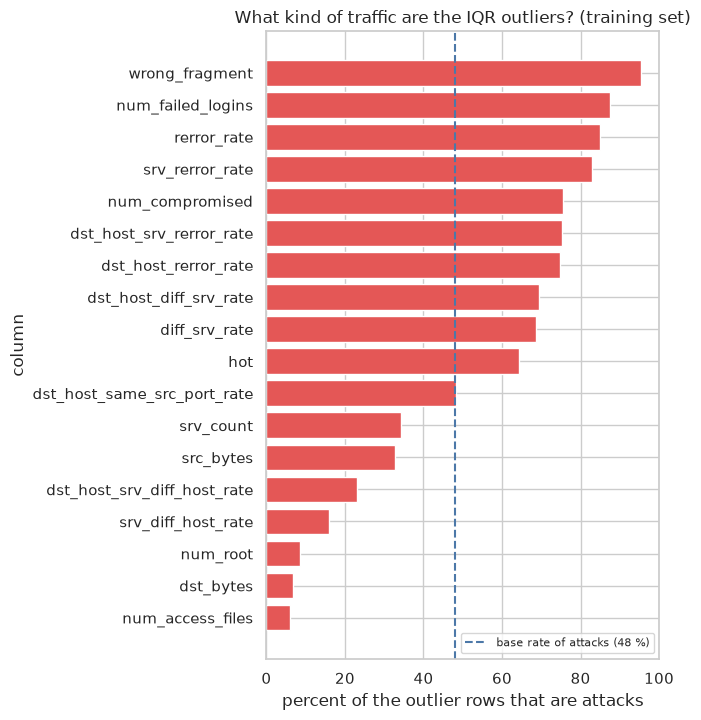

In [18]:
top = out_tbl[out_tbl["outliers"] >= 300].sort_values("% of outliers that are attacks")
fig, ax = plt.subplots(figsize=(7, 0.32 * len(top) + 1.6))
ax.barh(top["column"], top["% of outliers that are attacks"], color="#E45756")
ax.axvline(base, ls="--", color="#4C78A8", label=f"base rate of attacks ({base:.0f} %)")
ax.set_xlabel("percent of the outlier rows that are attacks"); ax.set_ylabel("column")
ax.set_title("What kind of traffic are the IQR outliers? (training set)")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

**Reading the result.** The IQR rule flags a lot of rows (10–23 % in several columns), so it is clearly not pointing at a few typing errors. The share of attacks *inside* the outlier rows then tells us what these rows are. If they were random noise, that share would sit at the 48 % base rate. Instead it is **far from 48 % in almost every column, in both directions**:

- **Attack-heavy outliers:** error rates (`rerror_rate` 85 %, `dst_host_rerror_rate` 75 %), `wrong_fragment` (95 %), `num_failed_logins` (88 %) are the footprints of scans, floods and password guessing.
- **Normal-heavy outliers:** `dst_bytes` outliers are only 7 % attacks (large downloads by ordinary users), and `su_attempted`, `num_root`, `num_access_files` outliers are mostly normal admin activity.
- Only `dst_host_same_src_port_rate` sits near the base rate (48 %); it is a 0–1 rate, and the check above confirms every rate is inside [0, 1].

**Decision.**
- **They are genuine values, not errors.** No rate is outside [0, 1] and nothing is negative. Real errors would look like impossible values, and there are none.
- **They carry information about the class.** Because the outlier rows deviate strongly from the base rate in both directions, deleting them would throw away signal an IDS depends on.
- **Treatment: keep all rows; reduce their influence instead.** The `log1p` transform of Stage E already shrinks the giant byte/count values, and one of our baseline models is a Random Forest, which is insensitive to extreme values. If a value were an error (e.g. a negative byte count) we would clip or remove it; there is none.
- **Limit of the IQR rule here.** For zero-inflated columns the IQR is 0, so *every* non-zero value is flagged (marked `yes` in the table). These flags only say "rare", not "wrong", which is why we judged them by the attack share and the validity check and not by the flag alone.

### Assemble and fit the whole pipeline on the training set
All pieces collected in `steps` are now combined into one `ColumnTransformer`. Calling `.fit()` on `X_train` only means every imputer, encoder, bin edge and scaler learns from the training rows. The test set is only ever `.transform()`-ed.

In [19]:
preprocessor = ColumnTransformer(steps, remainder="drop", verbose_feature_names_out=False)
preprocessor.set_output(transform="pandas")

X_train_p = preprocessor.fit_transform(X_train)      # FIT on training rows only
X_test_p  = preprocessor.transform(X_test)           # test rows are only transformed
print("Raw columns:", X_train.shape[1], "→ processed columns:", X_train_p.shape[1])
print("Missing values after preprocessing: train", int(X_train_p.isna().sum().sum()),
      " test", int(X_test_p.isna().sum().sum()))
display(X_train_p.iloc[:3, :8].round(3))

Raw columns: 41 → processed columns: 120
Missing values after preprocessing: train 0  test 0


,protocol_type_icmp,protocol_type_tcp,protocol_type_udp,service_IRC,service_X11,service_Z39_50,service_aol,service_auth
8972,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
28401,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
139330,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [20]:
# Proof of no leakage: the scaler's learned mean must equal the TRAINING mean of log1p(src_bytes),
# and must differ from the mean over train+test.
sc = preprocessor.named_transformers_["log_scaled"].named_steps["scale"]
j = log_cols.index("src_bytes")
train_mean = np.log1p(X_train["src_bytes"]).mean()
full_mean  = np.log1p(X_all["src_bytes"]).mean()
print(f"scaler mean for src_bytes : {sc.mean_[j]:.6f}")
print(f"training-set mean         : {train_mean:.6f}   (identical → fitted on train only)")
print(f"mean over ALL rows        : {full_mean:.6f}   (what a leaky fit would have used)")
assert np.isclose(sc.mean_[j], train_mean)

scaler mean for src_bytes : 3.288251
training-set mean         : 3.288251   (identical → fitted on train only)
mean over ALL rows        : 3.292100   (what a leaky fit would have used)


## Stage G – Dimensionality reduction / feature selection

One-hot encoding grew the feature count a lot (the `service` column alone adds 69 columns). More features means more noise, slower training and a higher risk of over-fitting, and many are redundant. We apply **feature selection** in two filters, both decided on the training rows only:

1. **Variance threshold** – remove columns with (almost) zero variance; they cannot help separate classes.
2. **Correlation filter** – when two columns are almost perfectly correlated (|r| > 0.95) they carry the same information, so we keep the first and drop the other.

*Why selection and not PCA?* PCA mixes all columns into abstract components, so we lose the meaning of the features. In ZeroWatch we explain every alert with SHAP using real feature names (`src_bytes`, `serror_rate`, ...), so we keep the original, named features. We still run PCA below as an analysis, to see how compressible the data is.

In [21]:
n_raw = X_train.shape[1]
n_encoded = X_train_p.shape[1]

# 1) variance threshold (computed on the training rows)
variances = X_train_p.var()
low_var = variances[variances < 1e-4].index.tolist()
after_var = [c for c in X_train_p.columns if c not in low_var]

# 2) correlation filter (computed on the training rows)
corr = X_train_p[after_var].corr().abs()
kept, dropped = [], {}
for c in after_var:
    partner = next((k for k in kept if corr.loc[c, k] > 0.95), None)
    if partner is None: kept.append(c)
    else: dropped[c] = (partner, round(float(corr.loc[c, partner]), 3))

print(f"Raw columns                           : {n_raw}")
print(f"After preprocessing (encoded/binned)  : {n_encoded}")
print(f"Removed by variance threshold         : {len(low_var)}  {low_var}")
print(f"Removed by correlation filter (>0.95) : {len(dropped)}")
for c, (p, r) in dropped.items(): print(f"    {c:28s} ~ {p:26s} |r| = {r}")
print(f"\nFinal number of features kept         : {len(kept)}")

Raw columns                           : 41
After preprocessing (encoded/binned)  : 120
Removed by variance threshold         : 7  ['service_aol', 'service_harvest', 'service_http_8001', 'service_red_i', 'service_tftp_u', 'service_urh_i', 'is_host_login']
Removed by correlation filter (>0.95) : 6
    serror_rate                  ~ flag_S0                    |r| = 0.973
    srv_serror_rate              ~ flag_S0                    |r| = 0.977
    srv_rerror_rate              ~ rerror_rate                |r| = 0.986
    dst_host_serror_rate         ~ flag_S0                    |r| = 0.969
    dst_host_srv_serror_rate     ~ flag_S0                    |r| = 0.976
    dst_host_srv_rerror_rate     ~ rerror_rate                |r| = 0.957

Final number of features kept         : 107


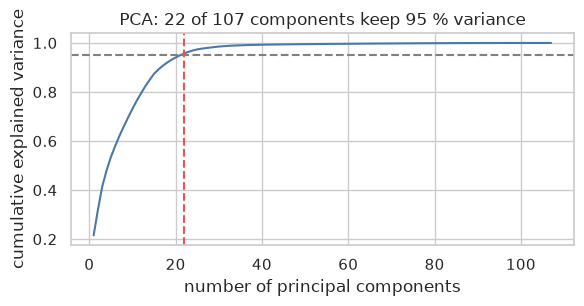

PCA (analysis only): 22 of 107 components are enough for 95 % of the variance.


In [22]:
X_train_s, X_test_s = X_train_p[kept], X_test_p[kept]      # same columns selected for train and test

# PCA as analysis only (not applied): how many components keep 95 % of the variance?
pca = PCA().fit(X_train_s)
cum = np.cumsum(pca.explained_variance_ratio_)
k95 = int(np.searchsorted(cum, 0.95) + 1)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(range(1, len(cum) + 1), cum, color="#4C78A8"); ax.axhline(0.95, ls="--", color="grey")
ax.axvline(k95, ls="--", color="#E45756")
ax.set_xlabel("number of principal components"); ax.set_ylabel("cumulative explained variance")
ax.set_title(f"PCA: {k95} of {len(kept)} components keep 95 % variance")
plt.tight_layout(); plt.show()
print(f"PCA (analysis only): {k95} of {len(kept)} components are enough for 95 % of the variance.")

**Result (counts from the cells above).**

| step | number of features |
|---|---|
| raw columns | 41 |
| after encoding, binning and the constant-column drop (3 nominal columns become 83 one-hot columns) | 120 |
| removed by variance threshold | 7 (six very rare services and the near-constant `is_host_login`) |
| removed by correlation filter (\|r\| > 0.95) | 6 (the `*_serror_rate` family is ~97 % correlated with the `flag_S0` one-hot column, and the `*_rerror_rate` family with `rerror_rate`) |
| **final features kept** | **107** |

PCA shows the data could be compressed a lot further (see the printed component count), but we keep named features so results stay interpretable.

## Stage H – Model training

The split was done in the very beginning, so the test set has been untouched by every fit. We train two simple baselines on the **preprocessed training data** and evaluate on the **preprocessed test data**:

- **Logistic Regression** – the simplest linear classifier. It needs scaled inputs (which is why Stage E matters).
- **Random Forest** – an ensemble of decision trees; robust to the extreme values we deliberately kept in Stage F.

Accuracy is *not* the marking criterion; we report it with precision, recall and F1. In intrusion detection, **recall** (the share of real attacks that we catch) is the metric to watch, and **precision** tells us how many alarms are false.

In [23]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
}
rows, fitted = [], {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    fitted[name] = pred
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, pred),
                 "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "train F1": f1_score(y_train, model.predict(X_train_s))})
results = pd.DataFrame(rows).set_index("model").round(4)
display(results)

,accuracy,precision,recall,F1,train F1
model,,,,,
Logistic Regression,0.9632,0.9669,0.9559,0.9614,0.9610
Random Forest,0.9961,0.9973,0.9945,0.9959,0.9995


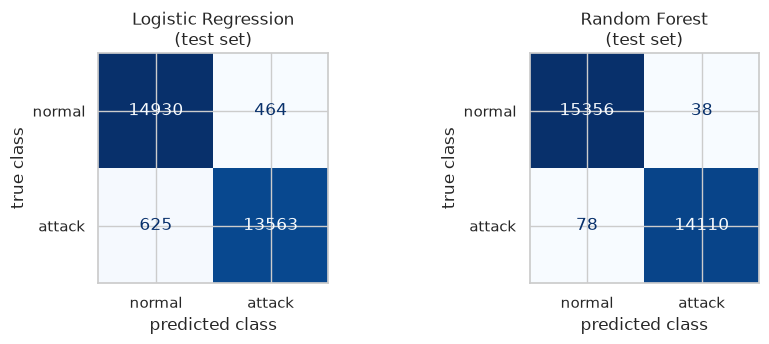

              precision    recall  f1-score   support

      normal     0.9949    0.9975    0.9962     15394
      attack     0.9973    0.9945    0.9959     14188

    accuracy                         0.9961     29582
   macro avg     0.9961    0.9960    0.9961     29582
weighted avg     0.9961    0.9961    0.9961     29582



In [24]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (name, pred) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["normal", "attack"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\n(test set)"); ax.set_xlabel("predicted class"); ax.set_ylabel("true class")
plt.tight_layout(); plt.show()
print(classification_report(y_test, fitted["Random Forest"], target_names=["normal", "attack"], digits=4))

## Results and observations
- **Both baselines learn the task once the data is prepared.** On the held-out test set the Random Forest reaches F1 ≈ 0.996 and Logistic Regression F1 ≈ 0.961 (exact values in the table above). The linear model working this well is a consequence of Stage E: the log transform and scaling made the features comparable.
- **No sign of over-fitting beyond the usual.** Logistic Regression's train and test F1 are almost identical. The Random Forest scores slightly higher on training data (0.9995 vs 0.996), as tree ensembles typically do, but the gap is small.
- **The honest limit of these numbers.** A random split puts all attack *families* into both train and test, so a score near 99.6 % mostly says "the model recognises attack types it was shown". It does **not** say it can catch a brand-new attack. That harder question is the point of ZeroWatch, and its leave-one-attack-category-out evaluation scores much lower. We therefore treat this accuracy as a sanity check on the preprocessing, not as the project's result.
- **Outliers were information, not noise.** The attack share inside outlier rows ranged from 1.5 % to 95 % against a 48 % base rate, so deleting them would have removed signal in both directions.
- **Feature selection** removed 7 + 6 redundant columns with no loss of named, explainable features.

**Challenges and what we would do differently**
- The dataset has no missing values, so Stage B is a documented decision plus a safety net. On a messier dataset (for example CICIDS2017, which contains `NaN` and `inf` values) the imputers would do real work.
- `service` creates 69 one-hot columns, many of them rare. Grouping rare services into an "other" bucket would shrink the feature space further.
- Zero-inflated count columns stay skewed after `log1p`; an alternative would be to turn them into 0/1 "occurred or not" flags.
- Evaluate with a leave-one-attack-category-out split to measure real zero-day ability (done in `ml/scripts/`).

## References and tools used
- NSL-KDD dataset: M. Tavallaee, E. Bagheri, W. Lu, A. Ghorbani, *"A detailed analysis of the KDD CUP 99 data set"*, IEEE CISDA 2009. Files loaded from the public mirror `github.com/jmnwong/NSL-KDD-Dataset`.
- scikit-learn user guide, used for `ColumnTransformer`, `OneHotEncoder`, `OrdinalEncoder`, `KBinsDiscretizer`, `SimpleImputer`, `StandardScaler`, `PCA` and the metrics.
- An AI assistant (Claude, Anthropic) was used to help structure the notebook and draft the code and explanations. We reviewed each step, and each member can explain every part (viva requirement).